# Neural Network traning er time , ephoc koto nibo?
- 100, 1000 or more?

Ans is: jodi beshi maximum epoch diya model train korle, maje moddhe overfitting er change thake.

Example in below:

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pylab import rcParams
import warnings

from mlxtend.plotting import plot_decision_regions
from matplotlib.colors import ListedColormap

import tensorflow 
from tensorflow import keras

In [23]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping


from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

In [24]:
X,y = make_circles(n_samples=100, noise=0.1, random_state=1)

In [25]:
X[:,0]

array([-0.63640493, -0.24465976, -0.46597138, -0.70999784,  0.70232238,
       -0.49776571, -0.31914906, -0.57839322, -0.53350227, -0.24733259,
        0.41030774,  0.17181003,  0.65917045,  0.87625577,  0.81946243,
       -0.47960986, -0.90187751,  0.74827659, -0.74875324,  0.23161178,
        0.81387506, -0.92169575,  0.74650434,  0.01330079, -0.72651409,
       -0.33930852,  0.49009938, -0.9539309 ,  0.6927241 ,  0.003546  ,
       -0.35077763,  0.94798269,  0.52327611,  0.54670705,  0.10385825,
        0.31843503,  0.92901189,  0.20498887, -1.01797423, -0.51324637,
       -0.12292134,  0.71008749, -0.71742651, -0.13663998, -0.57877973,
        0.41812614,  0.84575703,  0.26707772, -0.87474347,  0.62430557,
        0.65495356,  0.57445296, -1.0617065 ,  0.96779554,  0.49980305,
        0.9717675 , -0.74061828,  0.08203902,  0.9202249 , -0.77079544,
       -0.8114891 , -0.3501353 , -0.74376426,  0.63771423,  0.75136154,
        0.22716539,  0.52855241,  0.33982534,  1.02669518,  0.17

<Axes: >

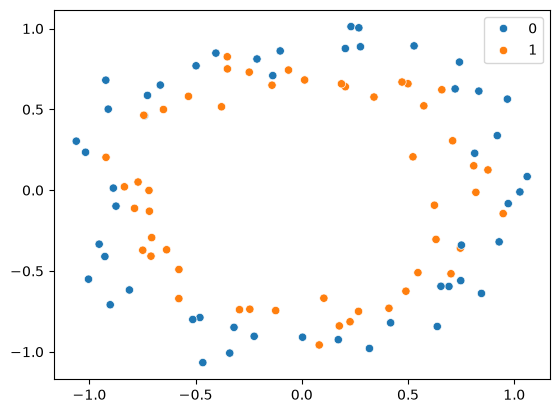

In [26]:
sns.scatterplot(x=X[:,0], y=X[:,1], hue=y)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2
)

In [28]:
model = Sequential()
model.add(Input(shape=(2,)))
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [29]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 256)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,025 (4.00 KB)

 Trainable params: 1,025 (4.00 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [31]:
history = model.fit(X_train, y_train, epochs=3500, validation_data=(X_test,y_test), verbose=0)

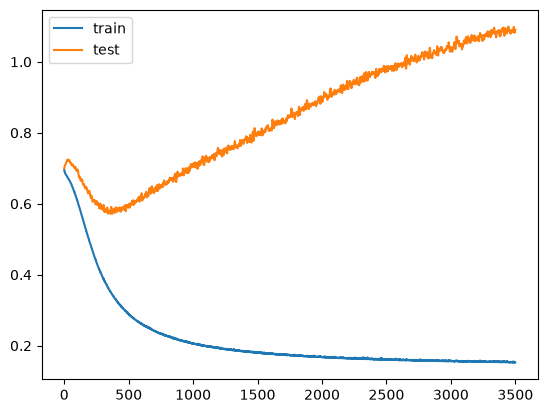

In [32]:
plt.plot(history.history['loss'], label= 'train')
plt.plot(history.history['val_loss'], label= 'test')
plt.legend()
plt.show()

In [38]:
class KerasClassifierWrapper:

    def __init__(self, model):
        self.model = model

    def predict(self, X):
        predictions = self.model.predict(X, verbose=0)
        return (predictions > 0.5).astype(int).ravel()
    

clf = KerasClassifierWrapper(model)

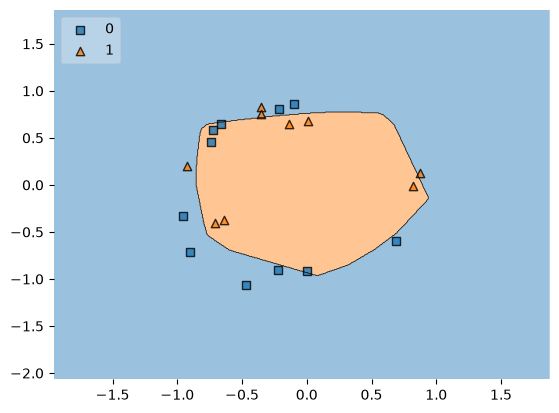

In [40]:
plot_decision_regions(
    X_test,
    y_test.ravel(),
    clf=clf,
    legend=2
)

plt.show()

we can see that there a overfitting: eikhane train and test er moddhe onk boro akta gap ase. and test er opor loss kisu ta kom suru korle akta porjai seita onk bere jai.

So, epoch onk beshi use korle sometimes model overfit hoy. eita tar example

Akon eitar solution hisebe early-stopping technique niya asa hoise. jeikhane jokhon dekhbe model er accuracy ar komse na. seita epoch stop hoya jabe

# Early-stopping
- eita callback e use kori. callback akta keras er library, jeita proti epoch e kisu kaj koriya nite pari

In [87]:
model = Sequential()
model.add(Input(shape=(2,)))
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [88]:
model.compile(loss='binary_crossentropy',optimizer='adam', metrics=['accuracy'])

In [94]:
callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.000001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False
)

In [95]:
history = model.fit(X_train, y_train, validation_data=(X_test,y_test), epochs=3500, callbacks=callback)

Epoch 1/3500


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.5875 - loss: 0.6652 - val_accuracy: 0.3500 - val_loss: 0.7171
Epoch 2/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5875 - loss: 0.6648 - val_accuracy: 0.4500 - val_loss: 0.7162
Epoch 3/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5875 - loss: 0.6637 - val_accuracy: 0.4000 - val_loss: 0.7156
Epoch 4/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.5875 - loss: 0.6631 - val_accuracy: 0.4500 - val_loss: 0.7144
Epoch 5/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5875 - loss: 0.6624 - val_accuracy: 0.4000 - val_loss: 0.7139
Epoch 6/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.6000 - loss: 0.6616 - val_accuracy: 0.4500 - val_loss: 0.7133
Epoch 7/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6250 - loss: 0.6609 - val_accuracy: 0.4500 - val_loss: 0.7130
Epoch 8/3500
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6375 - loss: 0.6601 - val_accuracy: 0.4500 - val_loss: 0.71

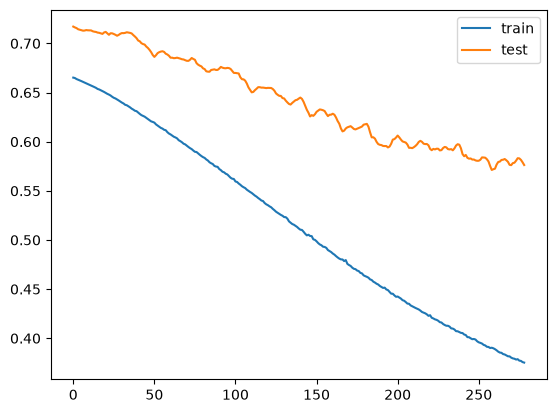

In [96]:
plt.plot(history.history['loss'], label = "train")
plt.plot(history.history['val_loss'], label = "test")
plt.legend()
plt.show()

In [97]:
class KerasClassifierWrapper:

    def __init__(self, model):
        self.model = model

    def predict(self, X):
        predictions = self.model.predict(X, verbose=0)
        return (predictions > 0.5).astype(int).ravel()
    

clf = KerasClassifierWrapper(model)

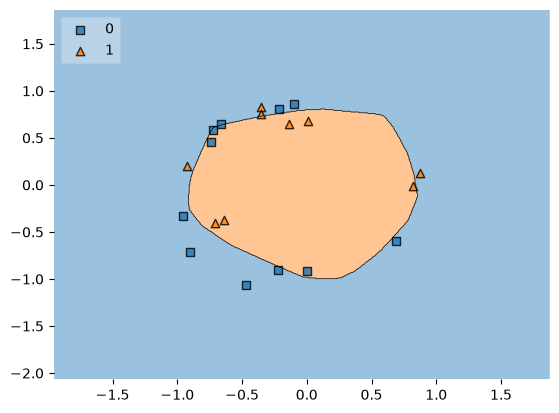

In [98]:
plot_decision_regions(
    X_test,
    y_test.ravel(),
    clf=clf,
    legend=2
)

plt.show()